# Vanilla options : pricing tests

European, Bermudan and American calls and puts priced with the Monte Carlo engine (`Model/monte_carlo.py`)
on the products of `Produits/products.py`:
1. validation against the Black-Scholes formula in a flat market;
2. CAC40 under the calibrated Heston model: Monte Carlo against the semi-analytical Lewis price;
3. early exercise premium (Longstaff-Schwartz);
4. Greeks.

In [1]:
import os, sys, time
sys.path.append(os.path.abspath(os.path.join("..", "..", "Model")))   # models, Monte Carlo engine, Greeks
sys.path.append(os.path.abspath(".."))                                # Produits : products.py, market.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from market import cac40_heston, flat_market
from products import Exercise, VanillaOption, BarrierOption, DigitalOption, DigitalBarrierOption
from monte_carlo import MonteCarloPricer
from greeks import Greeks, bump_spot, plot_greeks_bars, plot_greek_profiles

pd.set_option("display.float_format", lambda x: f"{x:.6g}")

## 1. Payoffs

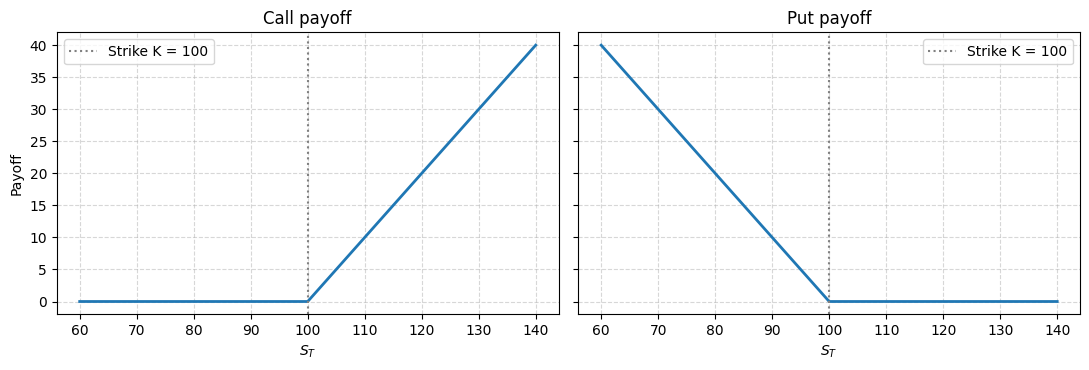

In [2]:
S = np.linspace(60, 140, 401)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, isCall in zip(axes, [True, False]):
    ax.plot(S, VanillaOption(100, 1.0, isCall).payoff(S), linewidth=2)
    ax.axvline(100, color="grey", linestyle=":", label="Strike K = 100")
    ax.set_title(f"{'Call' if isCall else 'Put'} payoff")
    ax.set_xlabel("$S_T$")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()
axes[0].set_ylabel("Payoff")
plt.tight_layout()
plt.show()

## 2. Validation in a flat Black-Scholes market

$S_0 = 100$, $r = 3\%$, $q = 1\%$, $\sigma = 20\%$. The Heston model with $v_0 = \theta = \sigma^2$ and no
vol-of-vol is a Black-Scholes model: the European Monte Carlo price must match the Black formula. The control
variate is switched off (it would be the option itself).

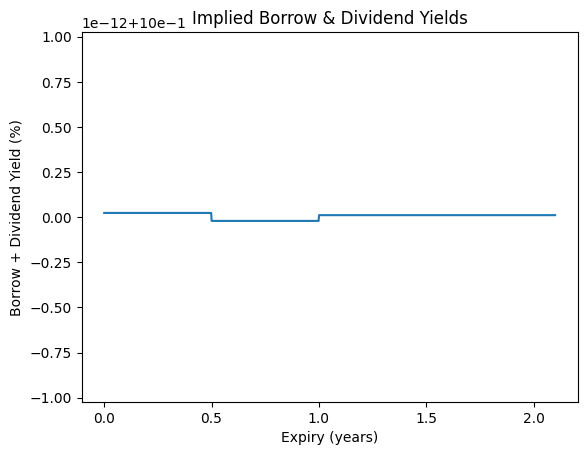

,Black,Monte Carlo,Std error,Error / std error
Option,,,,
Call K=80,22.3185,22.3231,0.0220189,0.207056
Put K=80,0.949207,0.949941,0.00968533,0.0757933
Call K=90,14.6592,14.6715,0.0291879,0.422255
Put K=90,2.99429,3.00279,0.0169962,0.500093
Call K=100,8.82732,8.84226,0.032965,0.453223
Put K=100,6.86689,6.87801,0.0212189,0.523848
Call K=110,4.89467,4.90679,0.0293847,0.412203
Put K=110,12.6387,12.647,0.017215,0.481405
Call K=120,2.52158,2.52664,0.0227389,0.222182


In [3]:
flat = flat_market()
raw = MonteCarloPricer(n_paths=100_000, steps_per_year=252, seed=1, control_variate=False)
rows = []
for K in [80, 90, 100, 110, 120]:
    for isCall in [True, False]:
        mc = raw.price(flat.heston, VanillaOption(K, 1.0, isCall))
        exact = flat.bs_model.bs_price_vanilla(1.0, K, flat.sigma, isCall)
        rows.append({"Option": f"{'Call' if isCall else 'Put'} K={K}", "Black": exact, "Monte Carlo": mc.price,
                     "Std error": mc.stderr, "Error / std error": (mc.price - exact) / mc.stderr})
pd.DataFrame(rows).set_index("Option")

## 3. CAC40 under the calibrated Heston model

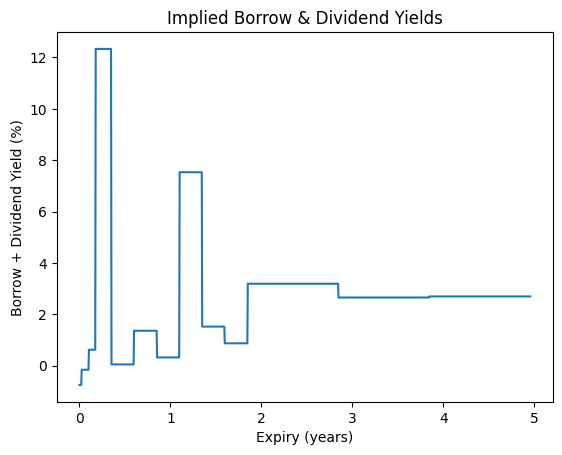

CAC40 2025-02-12 : S0 = 8042.19, 142 quotes on 13 expiries
Heston : v0=0.0197, theta=0.0438, kappa=1.3079, xi=0.4820, rho=-0.6050 | implied vol RMSE = 0.421 vol pts


In [4]:
mkt = cac40_heston()
heston, S0, T = mkt.heston, mkt.S0, 1.0
pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42)
raw = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42, control_variate=False)

In [5]:
rows = []
for K in [6800, 7200, 7600, 8000, 8400, 8800, 9200]:
    for isCall in [True, False]:
        mc = raw.price(heston, VanillaOption(K, T, isCall))
        exact = heston.price_vanilla(K, T, isCall)
        rows.append({"Option": f"{'Call' if isCall else 'Put'} K={K}", "Heston (Lewis)": exact, "Monte Carlo": mc.price,
                     "Std error": mc.stderr, "Error / std error": (mc.price - exact) / mc.stderr})
pd.DataFrame(rows).set_index("Option")

,Heston (Lewis),Monte Carlo,Std error,Error / std error
Option,,,,
Call K=6800,1348.75,1348.14,3.01046,-0.203181
Put K=6800,151.916,152.579,2.14166,0.309184
Call K=7200,1029.62,1028.54,2.7723,-0.39106
Put K=7200,223.574,223.764,2.53998,0.0746842
Call K=7600,740.316,738.902,2.54367,-0.555845
Put K=7600,325.053,324.913,2.92887,-0.0478181
Call K=8000,491.974,491.029,2.32002,-0.407417
Put K=8000,467.5,467.828,3.25674,0.100904
Call K=8400,297.063,296.716,2.05395,-0.169125


## 4. Early exercise

Bermudan (monthly) and American options are priced by Longstaff-Schwartz. The early exercise premium is the
difference with the European price. With low rates and a dividend yield, it is small for calls and larger for
deep in-the-money puts.

In [6]:
strikes = [6800, 7200, 7600, 8000, 8400, 8800, 9200]
exercises = {"European": Exercise.european(), "Bermudan (monthly)": Exercise.bermudan_every(T, 1 / 12),
             "American": Exercise.american()}
start = time.time()
table = {}
for isCall in [True, False]:
    for K in strikes:
        table[f"{'Call' if isCall else 'Put'} K={K}"] = {name: pricer.price(heston, VanillaOption(K, T, isCall, ex)).price
                                                         for name, ex in exercises.items()}
early = pd.DataFrame(table).T
early["American premium"] = early["American"] - early["European"]
print(f"{time.time() - start:.1f}s")
early

28.1s


,European,Bermudan (monthly),American,American premium
Call K=6800,1348.75,1358.73,1360.11,11.3606
Call K=7200,1029.62,1032.87,1032.77,3.14956
Call K=7600,740.316,741.044,740.092,-0.223447
Call K=8000,491.974,492.59,492.7,0.725473
Call K=8400,297.063,297.813,297.786,0.722354
Call K=8800,163.207,163.763,163.877,0.669797
Call K=9200,84.404,84.9322,85.1684,0.764397
Put K=6800,151.916,153.67,153.531,1.61467
Put K=7200,223.574,226.618,226.489,2.9153
Put K=7600,325.053,328.768,330.378,5.32465


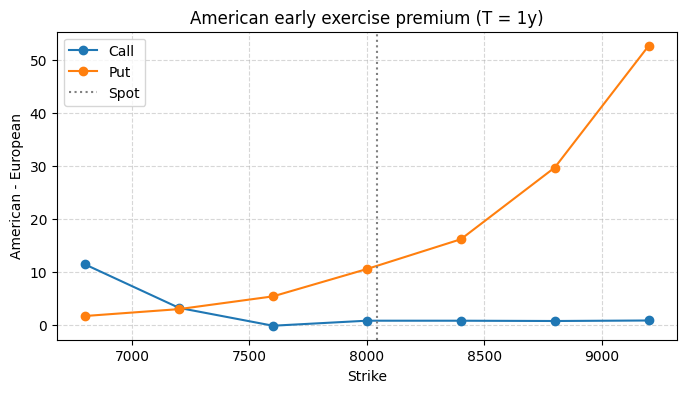

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
for kind in ["Call", "Put"]:
    ax.plot(strikes, [early.loc[f"{kind} K={K}", "American premium"] for K in strikes], "o-", label=kind)
ax.axvline(S0, color="grey", linestyle=":", label="Spot")
ax.set_title(f"American early exercise premium (T = {T:g}y)")
ax.set_xlabel("Strike")
ax.set_ylabel("American - European")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.show()

## 5. Greeks

Bump and revalue with common random numbers (`Model/greeks.py`). Units: Delta per unit of spot, Gamma per
unit of spot squared, Vega and Volga per vol point, Vanna as Delta change per vol point, Rho per +1% of rates,
Theta per calendar day.

In [8]:
greeks = Greeks(pricer)
options = [VanillaOption(8000, T, True), VanillaOption(8000, T, False),
           VanillaOption(8000, T, True, Exercise.american()), VanillaOption(8000, T, False, Exercise.american())]
labels = ["Call European", "Put European", "Call American", "Put American"]
start = time.time()
vanilla_greeks = greeks.table(heston, options, labels=labels, with_stderr=True)
print(f"{time.time() - start:.1f}s")
vanilla_greeks[[c for c in vanilla_greeks.columns if not c.endswith("stderr")]]

52.5s


,price,delta,gamma,vega,vanna,volga,rho,theta
Call European,491.974,0.616929,0.000332571,31.0078,-0.00214195,0.0874606,44.7219,-1.0018
Put European,467.5,-0.357958,0.000332571,31.0078,-0.00214195,0.0874612,-33.4357,-0.618007
Call American,492.7,0.617293,0.000291955,31.1992,-0.0027316,0.000294986,46.1679,-1.44745
Put American,477.993,-0.368758,0.000478544,31.8351,-0.00145714,0.399797,-30.9515,-1.2367


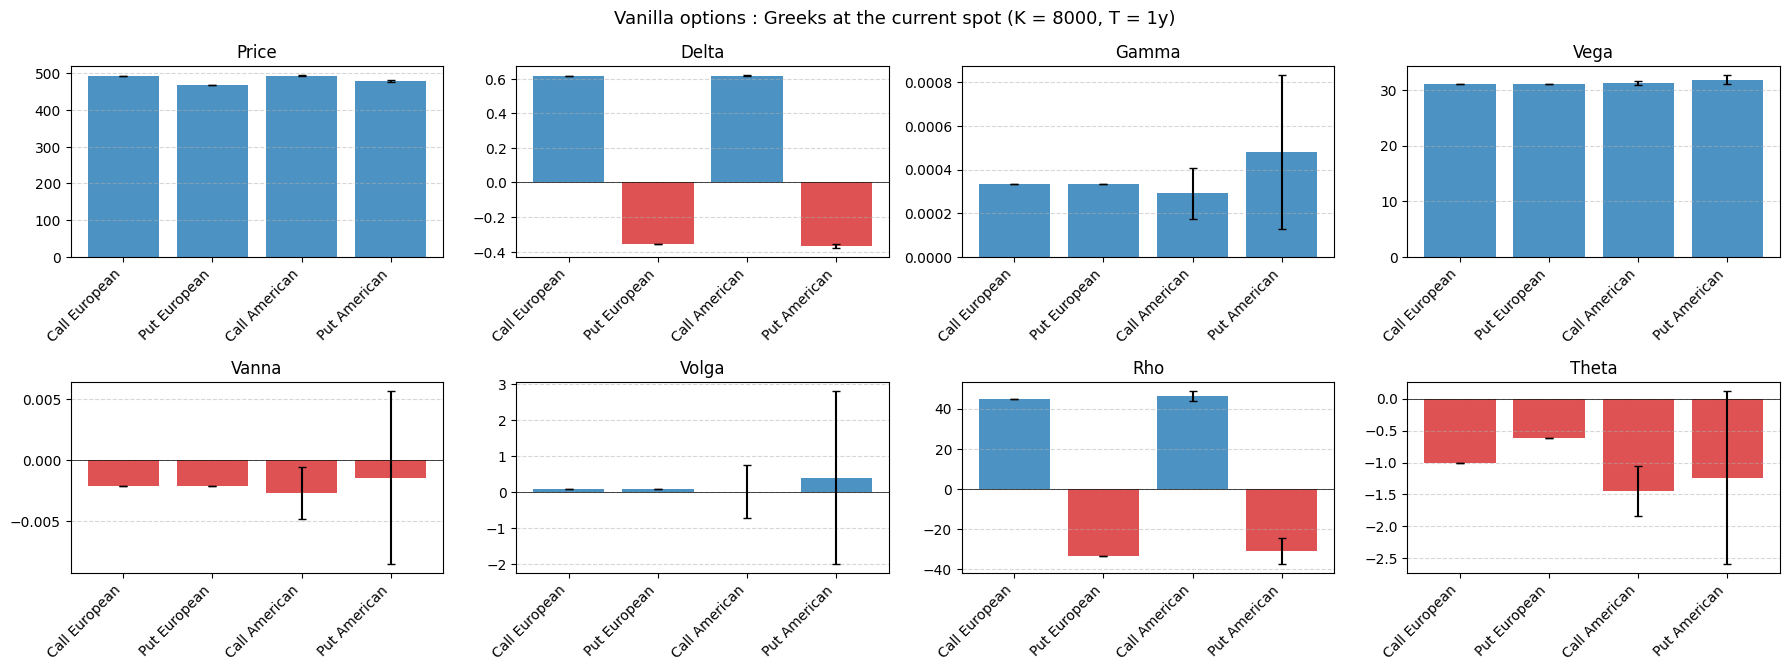

In [9]:
plot_greeks_bars(vanilla_greeks, title="Vanilla options : Greeks at the current spot (K = 8000, T = 1y)");

17.5s


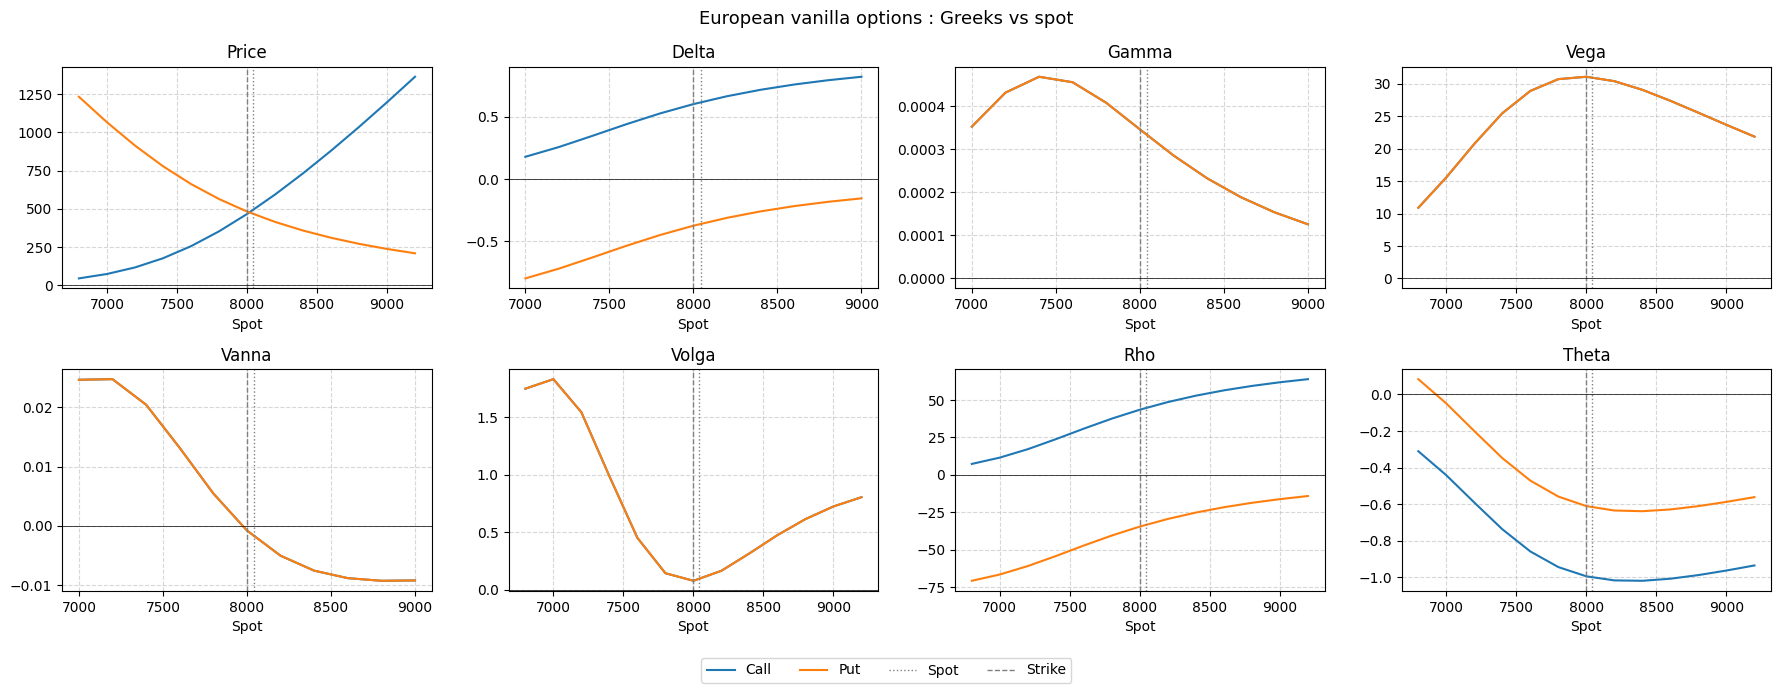

In [10]:
profile_pricer = MonteCarloPricer(n_paths=30_000, steps_per_year=252, seed=42)
start = time.time()
profiles = Greeks(profile_pricer).profiles(heston, options[:2], np.arange(6800.0, 9201.0, 200.0),
                                           labels=["Call", "Put"])
print(f"{time.time() - start:.1f}s")
plot_greek_profiles(profiles, vlines={"Spot": S0, "Strike": 8000}, title="European vanilla options : Greeks vs spot");